# Assignment 3: SGD, SCG and LeapFrog on six problems

This notebook holds the main experiment of the report. A neural network with one hidden layer
is trained by three algorithms:

* **SGD**: stochastic gradient descent with momentum
* **SCG**: scaled conjugate gradient (Møller, 1993)
* **LeapFrog**: the LeapFrog optimiser LFOP1(b) (Snyman, 1983)

The problems are three classification problems (wine, breast cancer, digits) and three
regression problems (diabetes, airfoil, California housing). The experiment has three steps:

1. **Step 1** chooses the number of hidden units with the one-standard-error rule.
2. **Step 2** tunes the control parameters of each algorithm with a grid search.
3. **Step 3** tests the tuned networks with five-fold cross-validation on the complete datasets.

### Contents
1. Settings
2. Figure style
3. The network
4. The training algorithms
5. The problems and the folds
6. Step 1: the number of hidden units
7. Step 2: the control parameters
8. Step 3: five-fold evaluation
9. Friedman and Nemenyi tests
10. Convergence
11. Test loss distributions
12. LeapFrog: gradient norms and the held-out spikes

### Running the notebook
The slow parts save their results as CSV files in `results/`. When a file exists, the notebook
reads it instead of training again, so a full run takes about a minute. Delete a CSV file to
repeat that part. Steps 1 and 2 together take about an hour. The airfoil and California housing
datasets are downloaded from OpenML and scikit-learn the first time.

## 1. Settings

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"          # one thread gives repeatable results
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn import datasets as ds
from sklearn.model_selection import KFold, StratifiedKFold

In [2]:
ALGORITHMS = ["SGD", "SCG", "LeapFrog"]
PROBLEMS = ["wine", "breast_cancer", "digits", "diabetes", "airfoil", "california"]
HIDDEN_UNIT_CANDIDATES = [1, 2, 3, 4, 6, 8, 12, 16, 24, 32, 48, 64, 96, 128]
N_FOLDS = 5             # folds of Steps 1 and 2
MAX_EPOCHS = 200        # gradient calculations per training run
MAX_PATTERNS = 5000     # size cap for Steps 1 and 2
SEED = 0                # folds of Step 1
TUNE_SEED = 1           # folds of Step 2
FINAL_N_FOLDS = 5       # folds of Step 3
FINAL_SPLIT_SEED = 42   # folds of Step 3

RESULTS = "results"        # all CSV files and figures go here
os.makedirs(RESULTS, exist_ok=True)
# One colour per algorithm in every figure
COLOURS = {"SGD": "#1769aa", "SCG": "#c36c18", "LeapFrog": "#008675"}

## 2. Figure style
The report figures have one small panel per problem, with the font and size of the report text.
They are saved in `results/figures` as PNG files (400 dpi, tight bounding box). The notebook also shows each figure as one 2 x 3 grid.

In [3]:
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif"],
                     "font.size": 10, "mathtext.fontset": "stix"})
FIGURES = os.path.join(RESULTS, "figures")
os.makedirs(FIGURES, exist_ok=True)
LABELS = {"SGD": "Stochastic gradient descent", "SCG": "Scaled conjugate gradient", "LeapFrog": "LeapFrog"}


def loss_name(name):
    """Name of the loss for the y-axis labels."""
    if name in ["diabetes", "airfoil", "california"]:
        return "MSE"
    return "Cross-entropy"


def small_panel(width=2.15, height=1.55, bottom=0.29, left=0.57):
    """One small figure panel for the report (sizes in inches)."""
    fig, ax = plt.subplots(figsize=(width, height))
    fig.subplots_adjust(left=left / width, right=0.95, bottom=bottom, top=0.96)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#dddddd", linewidth=0.5)
    return fig, ax

## 3. The network
One hidden layer of tanh units. Classification uses softmax outputs and the cross-entropy.
Regression uses one linear output and half the mean squared error. All weights are kept in one vector.

In [4]:
def make_network(n_inputs, n_hidden, n_outputs, task):
    """Store the layer sizes and the task (classification or regression)."""
    return {"n_inputs": n_inputs, "n_hidden": n_hidden, "n_outputs": n_outputs, "task": task}


def init_weights(net, seed):
    """Uniform weights in [-1/sqrt(fan-in), 1/sqrt(fan-in)], returned as one flat vector."""
    rng = np.random.RandomState(seed)
    n_in, n_hid, n_out = net["n_inputs"], net["n_hidden"], net["n_outputs"]
    W1 = rng.uniform(-1, 1, size=(n_hid, n_in)) / np.sqrt(n_in)
    b1 = rng.uniform(-1, 1, size=n_hid) / np.sqrt(n_in)
    W2 = rng.uniform(-1, 1, size=(n_out, n_hid)) / np.sqrt(n_hid)
    b2 = rng.uniform(-1, 1, size=n_out) / np.sqrt(n_hid)
    return np.concatenate([W1.ravel(), b1, W2.ravel(), b2])


def unpack_weights(w, net):
    """Split the flat weight vector into W1, b1 (hidden layer) and W2, b2 (output layer)."""
    n_in, n_hid, n_out = net["n_inputs"], net["n_hidden"], net["n_outputs"]
    a = n_hid * n_in
    b = a + n_hid
    c = b + n_out * n_hid
    return w[:a].reshape(n_hid, n_in), w[a:b], w[b:c].reshape(n_out, n_hid), w[c:]


def softmax(Z):
    """Row-wise softmax. Subtracting the row maximum avoids overflow."""
    Z = Z - Z.max(axis=1, keepdims=True)
    expZ = np.exp(Z)
    return expZ / expZ.sum(axis=1, keepdims=True)


def forward(w, X, net):
    """Return the hidden activations H and the network outputs Y."""
    W1, b1, W2, b2 = unpack_weights(w, net)
    H = np.tanh(X @ W1.T + b1)
    Z = H @ W2.T + b2
    if net["task"] == "classification":
        return H, softmax(Z)
    return H, Z


def compute_loss(w, X, T, net):
    """Cross-entropy for classification and half the mean squared error for regression."""
    H, Y = forward(w, X, net)
    n = X.shape[0]
    if net["task"] == "classification":
        return -np.sum(T * np.log(Y + 1e-12)) / n
    return 0.5 * np.sum((Y - T) ** 2) / n


def compute_gradient(w, X, T, net):
    """Backpropagation: the gradient of compute_loss with respect to the weight vector."""
    W1, b1, W2, b2 = unpack_weights(w, net)
    H, Y = forward(w, X, net)
    n = X.shape[0]
    delta_out = (Y - T) / n
    delta_hidden = delta_out @ W2 * (1 - H ** 2)
    return np.concatenate([(delta_hidden.T @ X).ravel(), delta_hidden.sum(axis=0),
                           (delta_out.T @ H).ravel(), delta_out.sum(axis=0)])


def compute_error(w, X, T, net):
    """Misclassification rate for classification and mean squared error for regression."""
    H, Y = forward(w, X, net)
    if net["task"] == "classification":
        return np.mean(np.argmax(Y, axis=1) != np.argmax(T, axis=1))
    return np.mean((Y - T) ** 2)

### Gradient check
The backpropagation gradient is compared with a central finite difference on random data.
Both differences should be close to zero.

In [5]:
rng = np.random.RandomState(1)
for task in ["classification", "regression"]:
    X = rng.randn(20, 4)
    T = np.eye(3)[rng.randint(0, 3, 20)] if task == "classification" else rng.randn(20, 1)
    net = make_network(4, 5, T.shape[1], task)
    w = init_weights(net, 0)
    numeric = np.zeros(len(w))
    for i in range(len(w)):
        step = np.zeros(len(w))
        step[i] = 1e-6
        numeric[i] = (compute_loss(w + step, X, T, net) - compute_loss(w - step, X, T, net)) / 2e-6
    print(task, "largest difference:", np.max(np.abs(compute_gradient(w, X, T, net) - numeric)))

classification largest difference: 2.1443315526004092e-10
regression largest difference: 1.1497464091902998e-10


## 4. The training algorithms
Every algorithm gets 200 gradient calculations. `callback(w)` is called after each one
and is only used to draw the convergence curves.

In [6]:
def train_sgd(w, X, T, net, learning_rate, momentum, batch_size, max_epochs, seed, callback=None):
    """Mini-batch gradient descent with momentum. One epoch is one pass over the training set."""
    rng = np.random.RandomState(seed)
    w = w.copy()
    velocity = np.zeros(len(w))
    n = X.shape[0]
    loss_history = []
    for epoch in range(max_epochs):
        order = rng.permutation(n)
        for start in range(0, n, batch_size):
            batch = order[start:start + batch_size]
            gradient = compute_gradient(w, X[batch], T[batch], net)
            velocity = momentum * velocity - learning_rate * gradient
            w = w + velocity
        loss_history.append(compute_loss(w, X, T, net))
        if callback:
            callback(w)
    return w, loss_history

In [7]:
def train_scg(w, X, T, net, sigma, lambda_1, max_epochs, callback=None):
    """Scaled conjugate gradient (Moller, 1993)."""
    w = w.copy()
    N = len(w)
    lam = lambda_1
    lam_bar = 0.0
    r = -compute_gradient(w, X, T, net)
    p = r.copy()
    success = True
    k = 1
    loss = compute_loss(w, X, T, net)
    loss_history = [loss]
    if callback:
        callback(w)
    delta = 0.0
    while len(loss_history) < max_epochs:
        if k > 10 * max_epochs:
            raise FloatingPointError("SCG exceeded trial limit")
        p_squared = p @ p
        if not np.isfinite(p_squared):
            raise FloatingPointError("SCG non-finite direction")
        if p_squared <= 0:
            break
        if success:
            sigma_k = sigma / np.sqrt(p_squared)
            gradient_shifted = compute_gradient(w + sigma_k * p, X, T, net)
            loss_history.append(loss)
            if callback:
                callback(w)
            s = (gradient_shifted + r) / sigma_k
            delta = p @ s
        delta = delta + (lam - lam_bar) * p_squared
        if delta <= 0:
            lam_bar = 2 * (lam - delta / p_squared)
            delta = -delta + lam * p_squared
            lam = lam_bar
        mu = p @ r
        if not np.isfinite([mu, delta]).all():
            raise FloatingPointError("SCG non-finite curvature")
        if mu == 0 or delta == 0:
            break
        alpha = mu / delta
        loss_new = compute_loss(w + alpha * p, X, T, net)
        Delta = 2 * delta * (loss - loss_new) / mu ** 2
        if Delta >= 0:
            w = w + alpha * p
            loss = loss_new
            r_new = -compute_gradient(w, X, T, net)
            loss_history.append(loss)
            if callback:
                callback(w)
            lam_bar = 0.0
            success = True
            if k % N == 0:
                p = r_new
            else:
                beta = (r_new @ r_new - r_new @ r) / mu
                p = r_new + beta * p
            r = r_new
            if Delta >= 0.75:
                lam = lam / 4
        else:
            lam_bar = lam
            success = False
        if Delta < 0.25:
            lam = lam + delta * (1 - Delta) / p_squared
        if np.linalg.norm(r) < 1e-10:
            break
        k = k + 1
    loss_history = loss_history[:max_epochs]
    while len(loss_history) < max_epochs:
        loss_history.append(loss)
    return w, loss_history

In [8]:
def train_leapfrog(w, X, T, net, dt, max_step, m, delta_1, max_epochs, callback=None, trace=None):
    """LeapFrog LFOP1(b) (Snyman, 1983). If trace is a list, every gradient calculation adds
    the time step, the gradient norm, the sharp-turn test and the restart test to it."""
    epsilon = 1e-5
    i, j, s, p = 0, 2, 0, 1.0
    w = w.copy()
    a = -compute_gradient(w, X, T, net)
    v = 0.5 * a * dt
    loss_history = [compute_loss(w, X, T, net)]
    if callback:
        callback(w)
    w_prev, v_prev, w_final = w, v, w
    stop = False
    while len(loss_history) < max_epochs and not stop:
        if np.linalg.norm(v) * dt < max_step:
            p = p + delta_1
            dt = p * dt
        else:
            v = max_step * v / (dt * np.linalg.norm(v))
        if s >= m:
            dt = dt / 2
            w = (w + w_prev) / 2
            v = (v + v_prev) / 4
            s = 0
        w_next = w + v * dt
        while len(loss_history) < max_epochs:
            a_next = -compute_gradient(w_next, X, T, net)
            v_next = v + a_next * dt
            loss_history.append(compute_loss(w_next, X, T, net))
            if callback:
                callback(w_next)
            if trace is not None:
                trace.append({"dt": dt, "gradient_norm": np.linalg.norm(a_next),
                              "sharp_turn": a_next @ a <= 0,
                              "restart": np.linalg.norm(v_next) <= np.linalg.norm(v)})
            w_final = w_next
            if a_next @ a > 0:
                s = 0
            else:
                s = s + 1
                p = 1.0
            if np.linalg.norm(a_next) <= epsilon:
                stop = True
                break
            if np.linalg.norm(v_next) > np.linalg.norm(v):
                i = 0
                w_prev, v_prev = w, v
                w, v, a = w_next, v_next, a_next
                break
            w_midpoint = (w_next + w) / 2
            i = i + 1
            if i <= j:
                v_next = (v_next + v) / 4
            else:
                v_next = np.zeros(len(w))
                j = 1
            w_prev, v_prev = w, v
            w, v, a = w_next, v_next, a_next
            w_next = w_midpoint
    while len(loss_history) < max_epochs:
        loss_history.append(loss_history[-1])
    return w_final, loss_history

In [9]:
# Default control parameters. Step 1 uses them and every grid of Step 2 contains them.
DEFAULT_PARAMS = {
    "SGD": {"learning_rate": 0.01, "momentum": 0.9, "batch_size": 32},
    "SCG": {"sigma": 1e-4, "lambda_1": 1e-6},
    "LeapFrog": {"dt": 0.5, "max_step": 1.0, "m": 3, "delta_1": 0.001},
}


def train_network(algorithm, w, X, T, net, params, max_epochs, seed, callback=None):
    """Train with SGD, SCG or LeapFrog and return the final weights and the loss history."""
    if algorithm == "SGD":
        return train_sgd(w, X, T, net, params["learning_rate"], params["momentum"],
                         params["batch_size"], max_epochs, seed, callback)
    if algorithm == "SCG":
        return train_scg(w, X, T, net, params["sigma"], params["lambda_1"], max_epochs, callback)
    return train_leapfrog(w, X, T, net, params["dt"], params["max_step"], params["m"],
                          params["delta_1"], max_epochs, callback)

## 5. The problems and the folds
Inputs are standardised with the training fold. Regression targets are standardised too,
and classification targets are one-hot encoded.

In [10]:
def subsample(X, y, task, max_patterns, seed):
    """Random sample of max_patterns rows. Classification keeps the class proportions."""
    if X.shape[0] <= max_patterns:
        return X, y
    rng = np.random.RandomState(seed)
    if task == "classification":
        keep = []
        for label in np.unique(y):
            index = np.where(y == label)[0]
            take = int(round(max_patterns * len(index) / len(y)))
            keep.append(rng.choice(index, size=take, replace=False))
        keep = np.concatenate(keep)
    else:
        keep = rng.choice(len(y), size=max_patterns, replace=False)
    keep.sort()
    return X[keep], y[keep]


def load_problems(max_patterns=MAX_PATTERNS):
    """Load the six datasets. max_patterns=None keeps every row."""
    raw = [("wine", "classification", *ds.load_wine(return_X_y=True)),
           ("breast_cancer", "classification", *ds.load_breast_cancer(return_X_y=True)),
           ("digits", "classification", *ds.load_digits(return_X_y=True)),
           ("diabetes", "regression", *ds.load_diabetes(return_X_y=True)),
           ("airfoil", "regression", *ds.fetch_openml(data_id=44957, return_X_y=True, as_frame=False)),
           ("california", "regression", *ds.fetch_california_housing(return_X_y=True))]
    problems = []
    for name, task, X, y in raw:
        X = np.asarray(X, dtype=np.float64)
        y = np.asarray(y)
        if task == "regression":
            y = y.astype(np.float64)
        if max_patterns is not None:
            X, y = subsample(X, y, task, max_patterns, SEED)
        problems.append({"name": name, "task": task, "X": X, "y": y})
    return problems


def make_splits(X, y, task, n_folds, seed):
    """Stratified folds for classification and ordinary folds for regression."""
    if task == "classification":
        return list(StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed).split(X, y))
    return list(KFold(n_splits=n_folds, shuffle=True, random_state=seed).split(X))


def prepare_fold(X, y, train_index, val_index, task):
    """Standardise with the training fold and build the target matrices."""
    X_train, X_val = X[train_index], X[val_index]
    mean = X_train.mean(axis=0)
    std = X_train.std(axis=0)
    std[std == 0] = 1.0
    X_train = (X_train - mean) / std
    X_val = (X_val - mean) / std
    if task == "classification":
        classes = list(np.unique(y))
        eye = np.eye(len(classes))
        T_train = eye[[classes.index(label) for label in y[train_index]]]
        T_val = eye[[classes.index(label) for label in y[val_index]]]
    else:
        y_mean, y_std = y[train_index].mean(), y[train_index].std()
        if y_std == 0:
            y_std = 1.0
        T_train = ((y[train_index] - y_mean) / y_std).reshape(-1, 1)
        T_val = ((y[val_index] - y_mean) / y_std).reshape(-1, 1)
    return X_train, T_train, X_val, T_val


def n_outputs(problem):
    """One output per class for classification and one output for regression."""
    if problem["task"] == "classification":
        return len(np.unique(problem["y"]))
    return 1


problems = load_problems()
for problem in problems:
    print(problem["name"], problem["X"].shape, n_outputs(problem), "outputs")

wine (178, 13) 3 outputs
breast_cancer (569, 30) 2 outputs
digits (1797, 64) 10 outputs
diabetes (442, 10) 1 outputs
airfoil (1503, 5) 1 outputs
california (5000, 8) 1 outputs


## 6. Step 1: the number of hidden units
Every size is trained on five folds with the default control parameters.
The results are saved, so the sweep only runs once.

In [11]:
def run_sweep(problem, algorithm):
    """Train every candidate size on five folds with the default control parameters."""
    X, y, task = problem["X"], problem["y"], problem["task"]
    rows = []
    splits = make_splits(X, y, task, N_FOLDS, SEED)
    for n_hidden in HIDDEN_UNIT_CANDIDATES:
        for fold, (train_index, val_index) in enumerate(splits):
            X_train, T_train, X_val, T_val = prepare_fold(X, y, train_index, val_index, task)
            net = make_network(X.shape[1], n_hidden, n_outputs(problem), task)
            w, _ = train_network(algorithm, init_weights(net, SEED + fold), X_train, T_train,
                                 net, DEFAULT_PARAMS[algorithm], MAX_EPOCHS, SEED + fold)
            rows.append({"problem": problem["name"], "algorithm": algorithm,
                         "hidden_units": n_hidden, "fold": fold,
                         "val_error": compute_error(w, X_val, T_val, net),
                         "train_error": compute_error(w, X_train, T_train, net)})
    return rows


SWEEP_FILE = os.path.join(RESULTS, "arch_sweep.csv")
if os.path.exists(SWEEP_FILE):
    sweep = pd.read_csv(SWEEP_FILE)
else:
    rows = []
    for problem in problems:
        for algorithm in ALGORITHMS:
            print("sweep:", problem["name"], algorithm)
            rows += run_sweep(problem, algorithm)
    sweep = pd.DataFrame(rows)
    sweep.to_csv(SWEEP_FILE, index=False)

The 15 validation errors of the three algorithms give one mean and one standard error per size.
The one-standard-error rule takes the smallest size whose mean is within one standard error of
the lowest mean. Diabetes uses two units instead of one, because one tanh unit makes the output
a monotone function of one weighted sum of the inputs.

In [12]:
CHOSEN_HIDDEN = {}
rows = []
for name in PROBLEMS:
    part = sweep[sweep["problem"] == name]
    means = part.groupby("hidden_units")["val_error"].mean()
    ses = part.groupby("hidden_units")["val_error"].std() / np.sqrt(15)
    lowest = means.idxmin()
    rule = min(h for h in means.index if means[h] <= means[lowest] + ses[lowest])
    chosen = 2 if name == "diabetes" else rule
    CHOSEN_HIDDEN[name] = chosen
    a = part[part["hidden_units"] == chosen].sort_values(["algorithm", "fold"])["val_error"].values
    b = part[part["hidden_units"] == lowest].sort_values(["algorithm", "fold"])["val_error"].values
    p = stats.ttest_rel(a, b).pvalue if chosen != lowest else np.nan
    rows.append({"problem": name, "one_SE_rule": rule, "chosen": chosen,
                 "lowest_mean": lowest, "error_chosen": means[chosen],
                 "error_lowest": means[lowest], "p_value": p})
print(pd.DataFrame(rows).round(4).to_string())

         problem  one_SE_rule  chosen  lowest_mean  error_chosen  error_lowest  p_value
0           wine            2       2           48        0.0186        0.0168   0.6809
1  breast_cancer            2       2          128        0.0305        0.0275   0.4656
2         digits           32      32           64        0.0356        0.0321   0.3127
3       diabetes            1       2            1        0.5294        0.5043   0.0107
4        airfoil           16      16           48        0.1401        0.1371   0.5066
5     california           32      32           32        0.2576        0.2576      NaN


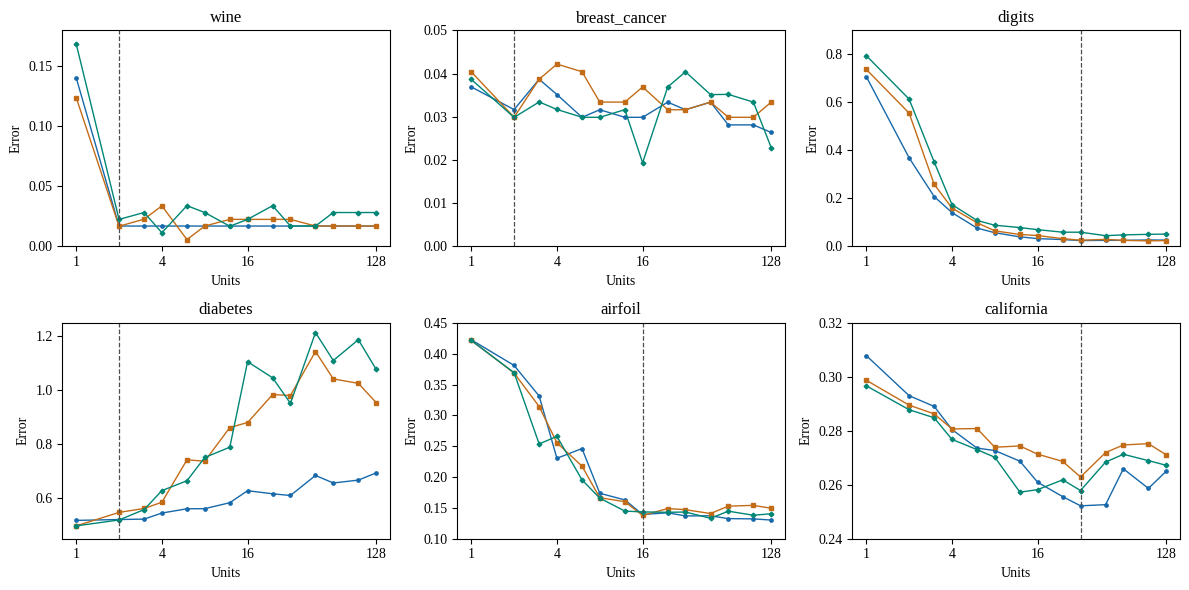

In [13]:
ERROR_RANGE = {"wine": (0, 0.18), "breast_cancer": (0, 0.05), "digits": (0, 0.9),
               "diabetes": (0.45, 1.25), "airfoil": (0.1, 0.45), "california": (0.24, 0.32)}
MARKERS = {"SGD": "o", "SCG": "s", "LeapFrog": "D"}


def plot_hidden_units(ax, name):
    """Mean validation error against the number of hidden units."""
    part = sweep[sweep["problem"] == name]
    for algorithm in ALGORITHMS:
        means = part[part["algorithm"] == algorithm].groupby("hidden_units")["val_error"].mean()
        ax.plot(means.index, means.values, marker=MARKERS[algorithm], markersize=2.4, linewidth=1, color=COLOURS[algorithm])
    ax.axvline(CHOSEN_HIDDEN[name], color="#4e4e4e", linestyle="--", linewidth=0.9)
    ax.set_xscale("log", base=2)
    ax.set_xlim(0.8, 160)
    ax.set_xticks([1, 4, 16, 128], ["1", "4", "16", "128"])
    ax.minorticks_off()
    ax.set_ylim(ERROR_RANGE[name])
    ax.set_xlabel("Units")
    ax.set_ylabel("Error")


for name in PROBLEMS:
    fig, ax = small_panel(left=0.63)
    plot_hidden_units(ax, name)
    fig.savefig(os.path.join(FIGURES, "hidden_units_" + name + ".png"), dpi=400, bbox_inches="tight")
    plt.close(fig)
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, name in zip(axes.ravel(), PROBLEMS):
    plot_hidden_units(ax, name)
    ax.set_title(name)
plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(6.8, 0.26))
handles = [plt.Line2D([], [], color=COLOURS[a], marker=MARKERS[a], markersize=3, label=LABELS[a]) for a in ALGORITHMS]
handles.append(plt.Line2D([], [], color="#4e4e4e", linestyle="--", label="Chosen size"))
fig.legend(handles=handles, loc="center", ncol=4, frameon=False)
fig.savefig(os.path.join(FIGURES, "hidden_units_legend.png"), dpi=400, bbox_inches="tight")
plt.close(fig)

## 7. Step 2: the control parameters
A grid search over five new folds. The default setting is part of every grid.

In [14]:
PARAM_GRIDS = {
    "SGD": [{"learning_rate": lr, "momentum": mom, "batch_size": batch}
            for lr in [0.001, 0.005, 0.02, 0.05, 0.1, 0.3]
            for mom in [0.0, 0.5, 0.9, 0.99]
            for batch in [16, 64]],
    "SCG": [{"sigma": sigma, "lambda_1": lam}
            for sigma in [1e-5, 1e-4, 1e-3]
            for lam in [1e-8, 1e-6, 1e-4]],
    "LeapFrog": [{"dt": dt, "max_step": max_step, "m": m, "delta_1": 0.001}
                 for dt in [0.1, 0.25, 0.5, 1.0]
                 for max_step in [0.5, 1.0, 2.0]
                 for m in [2, 3, 5]],
}
for algorithm in ALGORITHMS:
    if DEFAULT_PARAMS[algorithm] not in PARAM_GRIDS[algorithm]:
        PARAM_GRIDS[algorithm].insert(0, DEFAULT_PARAMS[algorithm])


def params_to_text(params):
    """Write a setting as text, for example 'sigma=0.0001, lambda_1=1e-06'."""
    return ", ".join(f"{name}={value}" for name, value in params.items())


def safe(value):
    """Replace nan and inf by inf, so that an unstable setting is never chosen."""
    return value if np.isfinite(value) else np.inf


def tune_one(problem, algorithm, params):
    """Train one setting on the five tuning folds."""
    X, y, task = problem["X"], problem["y"], problem["task"]
    rows = []
    for fold, (train_index, val_index) in enumerate(make_splits(X, y, task, N_FOLDS, TUNE_SEED)):
        X_train, T_train, X_val, T_val = prepare_fold(X, y, train_index, val_index, task)
        net = make_network(X.shape[1], CHOSEN_HIDDEN[problem["name"]], n_outputs(problem), task)
        start = time.perf_counter()
        w, _ = train_network(algorithm, init_weights(net, TUNE_SEED + fold), X_train, T_train,
                             net, params, MAX_EPOCHS, TUNE_SEED + fold)
        rows.append({"problem": problem["name"], "algorithm": algorithm,
                     "params": params_to_text(params), "fold": fold,
                     "val_error": safe(compute_error(w, X_val, T_val, net)),
                     "seconds": time.perf_counter() - start})
    return rows


np.seterr(over="ignore", invalid="ignore", divide="ignore")
TUNING_FILE = os.path.join(RESULTS, "tuning.csv")
if os.path.exists(TUNING_FILE):
    tuning = pd.read_csv(TUNING_FILE)
else:
    rows = []
    for problem in problems:
        for algorithm in ALGORITHMS:
            print("tuning:", problem["name"], algorithm)
            for params in PARAM_GRIDS[algorithm]:
                rows += tune_one(problem, algorithm, params)
    tuning = pd.DataFrame(rows)
    tuning.to_csv(TUNING_FILE, index=False)

The setting with the lowest mean validation error wins. `gain_%` is the improvement over the
default setting and `unstable` counts the settings with a diverged run.

In [15]:
means = tuning.groupby(["problem", "algorithm", "params"])["val_error"].mean()
BEST_PARAMS = {}
rows = []
for name in PROBLEMS:
    for algorithm in ALGORITHMS:
        part = means[name][algorithm]
        best = part.idxmin()                      # ties go to the first setting in sorted order
        settings = {params_to_text(p): p for p in PARAM_GRIDS[algorithm]}
        BEST_PARAMS[(name, algorithm)] = settings[best]
        default = part[params_to_text(DEFAULT_PARAMS[algorithm])]
        rows.append({"problem": name, "algorithm": algorithm, "best": best,
                     "error": part[best], "gain_%": 100 * (default - part[best]) / default,
                     "unstable": int((part > 100).sum())})
chosen_params = pd.DataFrame(rows)
print(chosen_params.round(4).to_string())
print(chosen_params.groupby("algorithm")["gain_%"].agg(["median", "max"]).round(2))
print("minutes of grid training:", (tuning[tuning["problem"].isin(PROBLEMS)].groupby("algorithm")["seconds"].sum() / 60).round(2).to_dict())

          problem algorithm                                               best   error   gain_%  unstable
0            wine       SGD   learning_rate=0.02, momentum=0.99, batch_size=64  0.0168  25.3521         0
1            wine       SCG                      sigma=0.0001, lambda_1=0.0001  0.0337   0.0000         0
2            wine  LeapFrog           dt=0.1, max_step=2.0, m=3, delta_1=0.001  0.0113   0.0000         0
3   breast_cancer       SGD   learning_rate=0.005, momentum=0.0, batch_size=64  0.0228  31.5814         0
4   breast_cancer       SCG                       sigma=0.0001, lambda_1=1e-06  0.0351   0.0000         0
5   breast_cancer  LeapFrog           dt=0.5, max_step=2.0, m=3, delta_1=0.001  0.0263  16.6503         0
6          digits       SGD     learning_rate=0.1, momentum=0.9, batch_size=16  0.0256  13.2081         0
7          digits       SCG                       sigma=0.001, lambda_1=0.0001  0.0267   3.9976         0
8          digits  LeapFrog          dt=0.25, 

## 8. Step 3: five-fold evaluation on the complete datasets
All three algorithms use the same folds and starting weights. The test loss is the
cross-entropy for classification and the full MSE for regression. The results are saved,
so the evaluation only runs once and the training times stay those of the report.

In [16]:
def evaluation_scores(w, X, T, net):
    """Return the error and the test loss (the cross-entropy, or the MSE for regression)."""
    error = float(compute_error(w, X, T, net))
    if net["task"] == "classification":
        return error, float(compute_loss(w, X, T, net))
    return error, error


def final_folds(problem):
    """The five folds of Step 3."""
    return make_splits(problem["X"], problem["y"], problem["task"], FINAL_N_FOLDS, FINAL_SPLIT_SEED)


final_problems = load_problems(max_patterns=None)
FINAL_FILE = os.path.join(RESULTS, "final.csv")
if os.path.exists(FINAL_FILE):
    final = pd.read_csv(FINAL_FILE)
else:
    rows = []
    for problem in final_problems:
        name, X, y, task = problem["name"], problem["X"], problem["y"], problem["task"]
        for fold, (train_index, test_index) in enumerate(final_folds(problem)):
            X_train, T_train, X_test, T_test = prepare_fold(X, y, train_index, test_index, task)
            net = make_network(X.shape[1], CHOSEN_HIDDEN[name], n_outputs(problem), task)
            for algorithm in ALGORITHMS:
                start = time.perf_counter()
                w, _ = train_network(algorithm, init_weights(net, FINAL_SPLIT_SEED + fold), X_train, T_train,
                                     net, BEST_PARAMS[(name, algorithm)], MAX_EPOCHS, FINAL_SPLIT_SEED + fold)
                seconds = time.perf_counter() - start
                test_error, test_loss = evaluation_scores(w, X_test, T_test, net)
                train_error, _ = evaluation_scores(w, X_train, T_train, net)
                rows.append({"problem": name, "algorithm": algorithm, "fold": fold + 1,
                             "test_error": test_error, "test_loss": test_loss,
                             "train_error": train_error, "seconds": seconds})
        print("final:", name)
    final = pd.DataFrame(rows)
    final.to_csv(FINAL_FILE, index=False)

In [17]:
summary = final.groupby(["problem", "algorithm"])[["test_error", "test_loss", "train_error", "seconds"]].agg(["mean", "std"])
summary = summary.reindex(PROBLEMS, level=0)
print(summary.round(3).to_string())

                        test_error        test_loss        train_error        seconds       
                              mean    std      mean    std        mean    std    mean    std
problem       algorithm                                                                     
wine          LeapFrog       0.023  0.024     0.325  0.302       0.001  0.003   0.012  0.003
              SCG            0.028  0.000     0.406  0.320       0.000  0.000   0.010  0.001
              SGD            0.028  0.020     0.226  0.173       0.000  0.000   0.027  0.002
breast_cancer LeapFrog       0.032  0.020     0.275  0.316       0.002  0.002   0.025  0.004
              SCG            0.042  0.031     0.370  0.267       0.001  0.001   0.022  0.002
              SGD            0.032  0.019     0.115  0.026       0.019  0.004   0.069  0.003
digits        LeapFrog       0.057  0.005     1.008  0.159       0.000  0.000   0.230  0.026
              SCG            0.023  0.005     0.195  0.051       0.000

## 9. Friedman and Nemenyi tests
Each problem is one block. The algorithms are ranked by their mean over the five folds.
When the Friedman test gives p < 0.05, two algorithms differ when their average ranks differ
by more than the Nemenyi critical difference $q_{0.05}\sqrt{k(k+1)/(6N)}$, with $q_{0.05} = 2.343$
for $k = 3$ algorithms and $N = 6$ problems (Demšar, 2006).

In [18]:
k, N = len(ALGORITHMS), len(PROBLEMS)
critical_difference = 2.343 * np.sqrt(k * (k + 1) / (6 * N))
for metric in ["test_loss", "test_error", "seconds"]:
    table = final.groupby(["problem", "algorithm"])[metric].mean().unstack()[ALGORITHMS].loc[PROBLEMS]
    ranks = table.rank(axis=1).mean()
    chi2, p = stats.friedmanchisquare(*[table[a] for a in ALGORITHMS])
    print(f"{metric}: ranks {ranks.round(2).to_dict()}, chi2 = {chi2:.2f}, p = {p:.4f}")
    if p < 0.05:
        for i in range(k):
            for j in range(i + 1, k):
                difference = abs(ranks.iloc[i] - ranks.iloc[j])
                if difference > critical_difference:
                    print(f"   {ALGORITHMS[i]} and {ALGORITHMS[j]} differ: {difference:.2f} > {critical_difference:.3f}")

test_loss: ranks {'SGD': 1.0, 'SCG': 2.67, 'LeapFrog': 2.33}, chi2 = 9.33, p = 0.0094
   SGD and SCG differ: 1.67 > 1.353
test_error: ranks {'SGD': 1.25, 'SCG': 2.67, 'LeapFrog': 2.08}, chi2 = 6.35, p = 0.0418
   SGD and SCG differ: 1.42 > 1.353
seconds: ranks {'SGD': 3.0, 'SCG': 1.0, 'LeapFrog': 2.0}, chi2 = 12.00, p = 0.0025
   SGD and SCG differ: 2.00 > 1.353


## 10. Convergence
The same final runs again, now recording the training loss and the held-out loss after every
gradient calculation (cross-entropy, or the full MSE for regression).
The curves are saved in `results/convergence.csv`, so they are only computed once.

In [19]:
CONVERGENCE_FILE = os.path.join(RESULTS, "convergence.csv")
if os.path.exists(CONVERGENCE_FILE):
    convergence = pd.read_csv(CONVERGENCE_FILE)
else:
    rows = []
    for problem in final_problems:
        name, X, y, task = problem["name"], problem["X"], problem["y"], problem["task"]
        for fold, (train_index, test_index) in enumerate(final_folds(problem)):
            X_train, T_train, X_test, T_test = prepare_fold(X, y, train_index, test_index, task)
            net = make_network(X.shape[1], CHOSEN_HIDDEN[name], n_outputs(problem), task)
            for algorithm in ALGORITHMS:
                history = []

                def record(w):
                    history.append((evaluation_scores(w, X_train, T_train, net)[1],
                                    evaluation_scores(w, X_test, T_test, net)[1]))

                train_network(algorithm, init_weights(net, FINAL_SPLIT_SEED + fold), X_train, T_train, net,
                              BEST_PARAMS[(name, algorithm)], MAX_EPOCHS, FINAL_SPLIT_SEED + fold, record)
                history = history[:MAX_EPOCHS]
                while len(history) < MAX_EPOCHS:
                    history.append(history[-1])
                for step, (train_loss, heldout_loss) in enumerate(history, start=1):
                    rows.append({"problem": name, "algorithm": algorithm, "fold": fold + 1, "step": step,
                                 "train_loss": train_loss, "heldout_loss": heldout_loss})
    convergence = pd.DataFrame(rows)
    convergence.to_csv(CONVERGENCE_FILE, index=False)

Each curve is the mean over the five folds and the shaded band spans one standard deviation on
either side of the mean. The training cross-entropy uses a logarithmic axis.

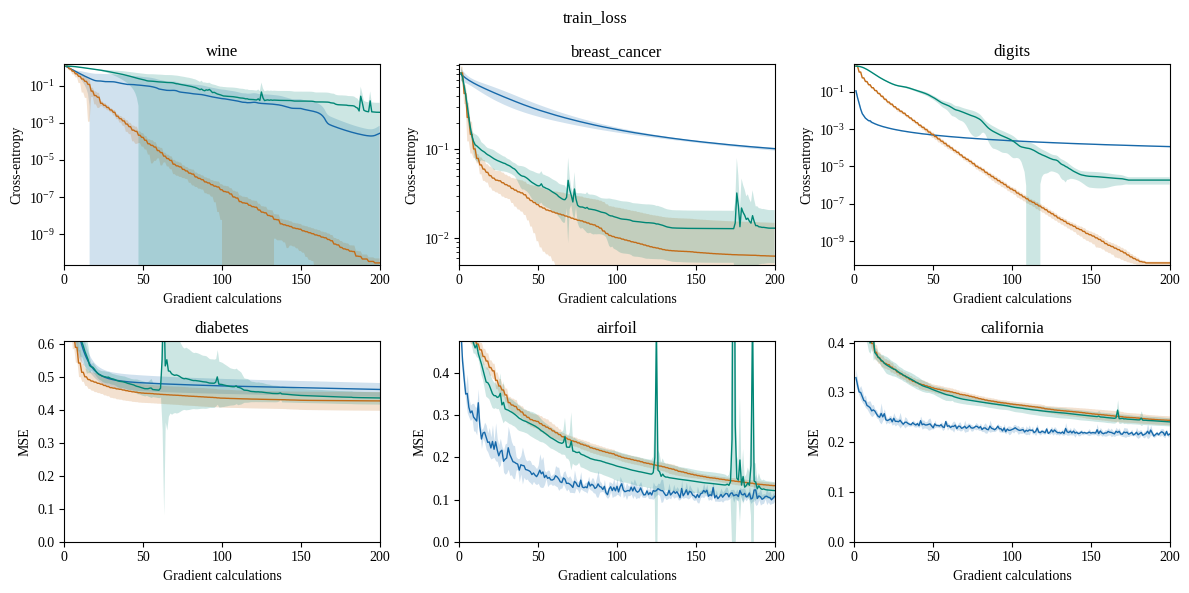

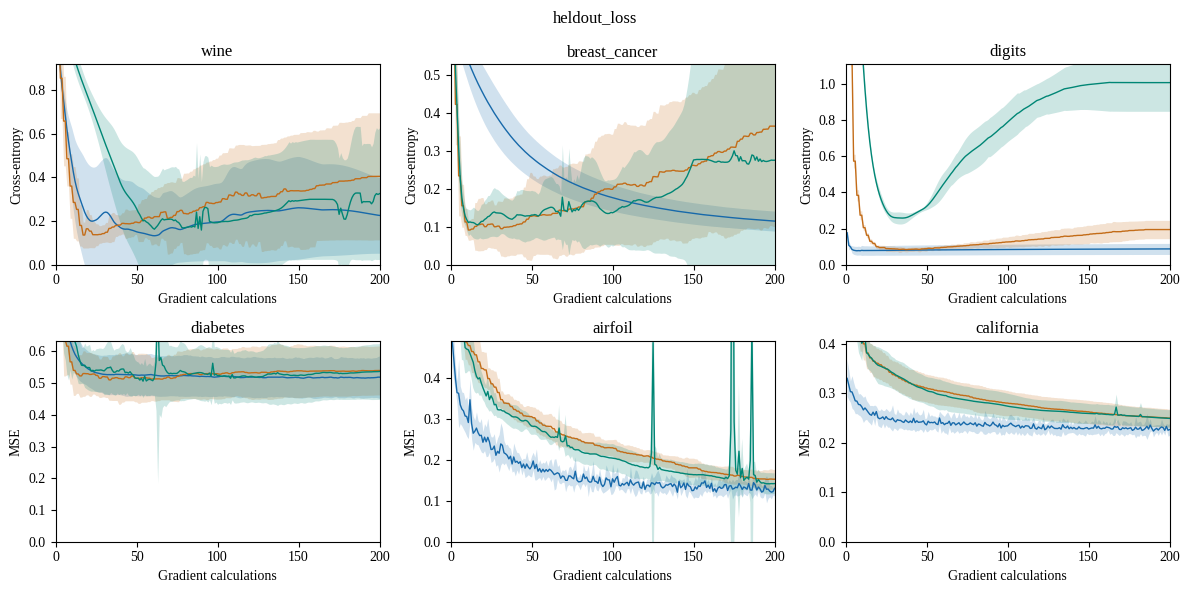

In [20]:
def plot_convergence(ax, name, column):
    """Mean curve over the five folds with a band of one standard deviation."""
    log_scale = column == "train_loss" and loss_name(name) == "Cross-entropy"
    lowest, highest = np.inf, 0
    for algorithm in ALGORITHMS:
        part = convergence[(convergence["problem"] == name) & (convergence["algorithm"] == algorithm)]
        mean = part.groupby("step")[column].mean()
        std = part.groupby("step")[column].std()
        ax.fill_between(mean.index, mean - std, mean + std, color=COLOURS[algorithm], alpha=0.2, linewidth=0)
        ax.plot(mean.index, mean, color=COLOURS[algorithm], linewidth=1)
        lowest = min(lowest, mean.min())
        if log_scale:
            highest = max(highest, mean.max())
        else:
            highest = max(highest, np.percentile(mean.values[10:], 97))
    if log_scale:
        ax.set_yscale("log")
        ax.set_ylim(0.8 * lowest, 1.25 * highest)
    else:
        ax.set_ylim(0, 1.1 * highest)
    ax.set_xlim(0, MAX_EPOCHS)
    ax.set_xticks([0, 50, 100, 150, 200])
    ax.set_xlabel("Gradient calculations")
    ax.set_ylabel(loss_name(name))


for column in ["train_loss", "heldout_loss"]:
    for name in PROBLEMS:
        fig, ax = small_panel()
        plot_convergence(ax, name, column)
        fig.savefig(os.path.join(FIGURES, column + "_" + name + ".png"), dpi=400, bbox_inches="tight")
        plt.close(fig)
    fig, axes = plt.subplots(2, 3, figsize=(12, 6))
    for ax, name in zip(axes.ravel(), PROBLEMS):
        plot_convergence(ax, name, column)
        ax.set_title(name)
    plt.suptitle(column)
    plt.tight_layout()
    plt.show()

fig = plt.figure(figsize=(6.8, 0.26))
fig.legend(handles=[plt.Line2D([], [], color=COLOURS[a], label=LABELS[a]) for a in ALGORITHMS],
           loc="center", ncol=3, frameon=False)
fig.savefig(os.path.join(FIGURES, "convergence_legend.png"), dpi=400, bbox_inches="tight")
plt.close(fig)

## 11. Test loss distributions
One box per algorithm over the five test folds. The box spans the quartiles, the line in the box
is the median, the whiskers reach the smallest and the largest loss and the red diamond is the mean.

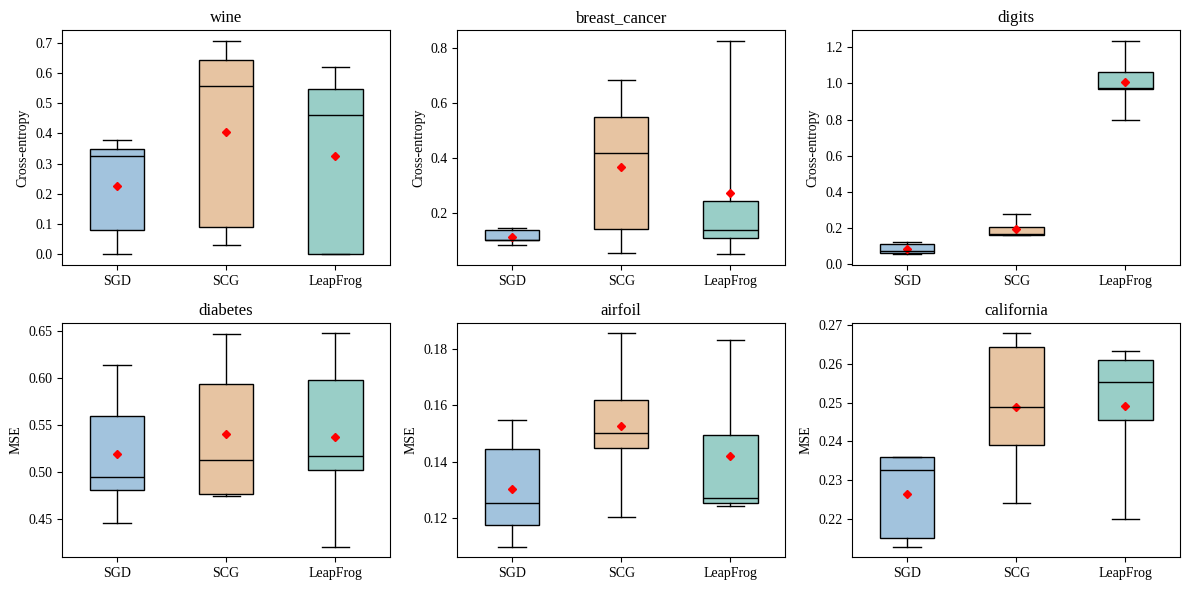

                          mean    std    min    max  range
problem       algorithm                                   
wine          LeapFrog   0.325  0.302  0.000  0.618  0.618
              SCG        0.406  0.320  0.031  0.706  0.675
              SGD        0.226  0.173  0.000  0.377  0.377
breast_cancer LeapFrog   0.275  0.316  0.052  0.827  0.774
              SCG        0.370  0.267  0.055  0.684  0.629
              SGD        0.115  0.026  0.084  0.146  0.062
digits        LeapFrog   1.008  0.159  0.798  1.235  0.436
              SCG        0.195  0.051  0.160  0.278  0.118
              SGD        0.087  0.031  0.057  0.125  0.068
diabetes      LeapFrog   0.537  0.088  0.421  0.647  0.226
              SCG        0.541  0.076  0.475  0.646  0.172
              SGD        0.519  0.067  0.446  0.613  0.167
airfoil       LeapFrog   0.142  0.025  0.125  0.183  0.059
              SCG        0.152  0.024  0.120  0.185  0.065
              SGD        0.130  0.019  0.110  0.155  0.0

In [21]:
def plot_test_losses(ax, name):
    """Box plot of the five test losses of each algorithm."""
    part = final[final["problem"] == name]
    losses = [part[part["algorithm"] == algorithm]["test_loss"].values for algorithm in ALGORITHMS]
    boxes = ax.boxplot(losses, whis=(0, 100), widths=0.5, patch_artist=True, medianprops={"color": "black"})
    for box, algorithm in zip(boxes["boxes"], ALGORITHMS):
        box.set_facecolor(COLOURS[algorithm] + "66")
    ax.plot([1, 2, 3], [values.mean() for values in losses], "D", color="red", markersize=4)
    ax.set_xticks([1, 2, 3], ALGORITHMS)
    ax.set_ylabel(loss_name(name))


for name in PROBLEMS:
    fig, ax = small_panel(bottom=0.17, left=0.66)
    plot_test_losses(ax, name)
    fig.savefig(os.path.join(FIGURES, "test_loss_" + name + ".png"), dpi=400, bbox_inches="tight")
    plt.close(fig)
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, name in zip(axes.ravel(), PROBLEMS):
    plot_test_losses(ax, name)
    ax.set_title(name)
plt.tight_layout()
plt.show()

spread = final.groupby(["problem", "algorithm"])["test_loss"].agg(["mean", "std", "min", "max"])
spread["range"] = spread["max"] - spread["min"]
print(spread.reindex(PROBLEMS, level=0).round(3).to_string())

## 12. LeapFrog: gradient norms and the held-out spikes
The LeapFrog runs of Step 3 on diabetes and airfoil are repeated with a trace. On a quadratic error
with largest Hessian eigenvalue lambda_max, the leapfrog scheme is stable only when
dt <= 2 / sqrt(lambda_max). The Hessian comes from central differences of the gradient.
The trace is saved in `results/leapfrog_trace.csv`, so it is only computed once.

In [22]:
def largest_eigenvalue(w, X, T, net):
    """Largest eigenvalue of the Hessian, from central differences of the gradient."""
    n = len(w)
    hessian = np.zeros((n, n))
    for i in range(n):
        step = np.zeros(n)
        step[i] = 1e-5
        hessian[:, i] = (compute_gradient(w + step, X, T, net) - compute_gradient(w - step, X, T, net)) / 2e-5
    return np.linalg.eigvalsh((hessian + hessian.T) / 2)[-1]


TRACE_FILE = os.path.join(RESULTS, "leapfrog_trace.csv")
if os.path.exists(TRACE_FILE):
    leapfrog_trace = pd.read_csv(TRACE_FILE)
else:
    rows = []
    for problem in final_problems:
        name, X, y, task = problem["name"], problem["X"], problem["y"], problem["task"]
        if name not in ["diabetes", "airfoil"]:
            continue
        params = BEST_PARAMS[(name, "LeapFrog")]
        for fold, (train_index, test_index) in enumerate(final_folds(problem)):
            X_train, T_train, X_test, T_test = prepare_fold(X, y, train_index, test_index, task)
            net = make_network(X.shape[1], CHOSEN_HIDDEN[name], n_outputs(problem), task)
            weights, trace = [], []
            train_leapfrog(init_weights(net, FINAL_SPLIT_SEED + fold), X_train, T_train, net, params["dt"],
                           params["max_step"], params["m"], params["delta_1"], MAX_EPOCHS, weights.append, trace)
            for step, (w, info) in enumerate(zip(weights[1:], trace), start=2):
                rows.append({"problem": name, "fold": fold + 1, "step": step, **info,
                             "train_mse": compute_error(w, X_train, T_train, net),
                             "heldout_mse": compute_error(w, X_test, T_test, net),
                             "limit": 2 / np.sqrt(largest_eigenvalue(w, X_train, T_train, net))})
    leapfrog_trace = pd.DataFrame(rows)
    leapfrog_trace.to_csv(TRACE_FILE, index=False)

A spike is a held-out MSE more than 20% above the lowest of the ten values before it. Flags less
than four gradient calculations apart belong to one spike. The run-up is the run of sharp turns that
ends at the peak. `growth` is the mean factor by which the gradient norm grew per gradient calculation
in the run-up and `predicted` is the factor of the quadratic model. `halved` counts the gradient
calculations from the peak to the halving of the time step. `back` counts the gradient calculations
after the peak until the held-out MSE is again within 5% of the level before the spike.

In [23]:
def predicted_growth(dt, limit):
    """Growth factor per step of the leapfrog scheme on a quadratic error with
    h = lambda_max * dt^2. The scheme is stable (factor 1) when h <= 4."""
    h = (2 * dt / limit) ** 2            # lambda_max * dt^2
    if h <= 4:
        return 1.0
    return (h - 2 + np.sqrt((h - 2) ** 2 - 4)) / 2


rows = []
for (name, fold), part in leapfrog_trace.groupby(["problem", "fold"]):
    part = part.reset_index(drop=True)
    heldout = part["heldout_mse"].values
    norm = part["gradient_norm"].values
    flags = [k for k in range(10, len(part)) if heldout[k] > 1.2 * heldout[k - 10:k].min()]
    groups = []
    for k in flags:
        if groups and k - groups[-1][-1] <= 3:
            groups[-1].append(k)
        else:
            groups.append([k])
    for group in groups:
        level = heldout[group[0] - 10:group[0]].min()
        peak = group[np.argmax(heldout[group])]
        first = peak
        while first > 1 and part["sharp_turn"][first - 1]:
            first -= 1
        if not part["sharp_turn"][peak]:
            first = peak
        halved = peak
        while halved < len(part) - 1 and part["dt"][halved + 1] > 0.75 * part["dt"][halved]:
            halved += 1
        back = peak
        while back < len(part) - 1 and heldout[back] > 1.05 * level:
            back += 1
        train_level = part["train_mse"][group[0] - 10:group[0]].min()
        rows.append({"problem": name, "fold": fold, "first": part["step"][first], "peak": part["step"][peak],
                     "rise": heldout[peak] / level, "train_rise": part["train_mse"][peak] / train_level,
                     "sharp_turns": int(part["sharp_turn"][first:peak + 1].sum()),
                     "dt": part["dt"][first], "limit": part["limit"][first],
                     "unstable": part["dt"][first] > part["limit"][first],
                     "growth": (norm[peak] / norm[first - 1]) ** (1 / (peak - first + 1)),
                     "predicted": predicted_growth(part["dt"][first], part["limit"][first]),
                     "restarts": int(part["restart"][first:peak + 1].sum()),
                     "halved": halved + 1 - peak, "back": back - peak})
spikes = pd.DataFrame(rows)
print(spikes.round(3).to_string())
print(len(spikes), "spikes,", int(spikes["unstable"].sum()), "with dt above the limit at the start of the run-up")
print("median growth:", round(spikes["growth"].median(), 2), " median rise:", round(spikes["rise"].median(), 2))

    problem  fold  first  peak    rise  train_rise  sharp_turns     dt  limit  unstable  growth  predicted  restarts  halved  back
0   airfoil     1     63    67   1.280       1.146            5  0.744  0.752     False   1.474      1.000         0       1     4
1   airfoil     1    170   174  41.142      43.681            5  0.601  0.508      True   2.834      3.290         0       1    12
2   airfoil     2    121   125   8.831      10.486            5  0.733  0.653      True   2.397      2.668         0       1     3
3   airfoil     3     67    71   1.407       1.357            5  0.791  0.775      True   1.625      1.502         0       1     1
4   airfoil     3    182   186  14.833      14.609            5  0.607  0.535      True   2.465      2.798         0       1     3
5   airfoil     5     63    67   1.376       1.322            5  0.721  0.712      True   1.535      1.391         0       1     1
6  diabetes     4     93    97   1.446       1.224            5  0.912  0.845      

### The largest spike: airfoil, fold 1

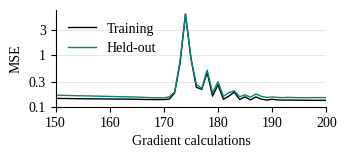

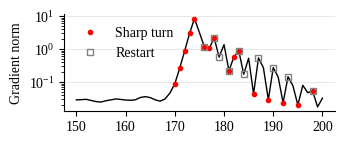

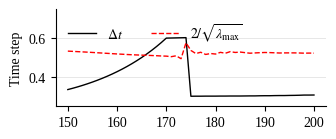

      problem  fold  step      dt  gradient_norm  sharp_turn  restart  train_mse  heldout_mse   limit
1157  airfoil     1   164  0.4845         0.0362       False    False     0.1397       0.1543  0.5142
1158  airfoil     1   165  0.5010         0.0339       False    False     0.1390       0.1533  0.5132
1159  airfoil     1   166  0.5185         0.0291       False    False     0.1382       0.1518  0.5124
1160  airfoil     1   167  0.5372         0.0264       False    False     0.1375       0.1506  0.5113
1161  airfoil     1   168  0.5571         0.0306       False    False     0.1373       0.1489  0.5102
1162  airfoil     1   169  0.5783         0.0462       False    False     0.1373       0.1486  0.5088
1163  airfoil     1   170  0.6008         0.0890        True    False     0.1373       0.1478  0.5081
1164  airfoil     1   171  0.6014         0.2644        True    False     0.1403       0.1549  0.5052
1165  airfoil     1   172  0.6020         0.8750        True    False     0.1844  

In [24]:
part = leapfrog_trace[(leapfrog_trace["problem"] == "airfoil") & (leapfrog_trace["fold"] == 1)]
part = part[part["step"] >= 150]
turns = part[part["sharp_turn"]]
restarts = part[part["restart"]]
panels = []

fig, ax = small_panel(3.45, 1.45)
ax.plot(part["step"], part["train_mse"], color="black", linewidth=1, label="Training")
ax.plot(part["step"], part["heldout_mse"], color=COLOURS["LeapFrog"], linewidth=1, label="Held-out")
ax.set_yscale("log")
ax.set_yticks([0.1, 0.3, 1, 3], ["0.1", "0.3", "1", "3"])
ax.minorticks_off()
ax.set_ylabel("MSE")
ax.legend(frameon=False, loc="upper left")
panels.append((fig, ax, "spike_mse"))

fig, ax = small_panel(3.45, 1.45)
ax.plot(part["step"], part["gradient_norm"], color="black", linewidth=1)
ax.plot(turns["step"], turns["gradient_norm"], "o", color="red", markersize=3, label="Sharp turn")
ax.plot(restarts["step"], restarts["gradient_norm"], "s", color="grey", markerfacecolor="none",
        markersize=5, label="Restart")
ax.set_yscale("log")
ax.set_ylabel("Gradient norm")
ax.legend(frameon=False, loc="upper left")
panels.append((fig, ax, "spike_gradient"))

fig, ax = small_panel(3.45, 1.45)
ax.plot(part["step"], part["dt"], color="black", linewidth=1, label=r"$\Delta t$")
ax.plot(part["step"], part["limit"], "--", color="red", linewidth=1, label=r"$2/\sqrt{\lambda_{\max}}$")
ax.set_ylim(0.25, 0.75)
ax.set_ylabel("Time step")
ax.legend(frameon=False, loc="upper left", ncol=2)
panels.append((fig, ax, "spike_time_step"))

for fig, ax, file_name in panels:
    ax.set_xlim(150, 200)
    ax.set_xlabel("Gradient calculations")
    fig.savefig(os.path.join(FIGURES, file_name + ".png"), dpi=400, bbox_inches="tight")
    plt.show()
print(part[(part["step"] >= 164) & (part["step"] <= 178)].round(4).to_string())

## Other notebooks
* `2_bayesian_optimisation.ipynb` tunes the control parameters with Bayesian optimisation and
  compares the result with the grid search of Step 2.
* `3_pytorch_version.ipynb` repeats the experiment with the network and the algorithms written in PyTorch.